# Alertas clínicas tempranas del programa canguro

El modelo de anomalías (`modelo_anomalias.ipynb`) pregunta si un **dato** está bien anotado. Este pregunta si un **niño** va hacia un problema. Son preguntas distintas: el de anomalías aprende lo normal de esta base, que es de niños prematuros o de bajo peso, así que un problema común en el programa le parece normal. Aquí lo normal no se aprende de la base:

| Señal | Cómo decide | Por qué no le afecta que la base sea de niños con problemas |
|---|---|---|
| **Crecimiento** | Puntaje z contra la curva de la OMS, por edad corregida, desde las 40 semanas. Marca por debajo de -2 DE o si cae más de 1 DE entre visitas | Es una regla externa: no aprende de la base |
| **Riesgo de un desenlace** | Un LightGBM por desenlace, con lo que se sabe en la visita y nada posterior. Da una probabilidad calibrada | Aprende justamente qué antecede a los malos desenlaces |

Todo lo específico del programa (qué desenlaces, en qué visita, qué curva, qué significa cada código) está en `clinico/configuracion.py`. El modelo de anomalías y SEVARTI no cambian; los datos que el de anomalías reconoce como errores (códigos, unidades, valores a más de 6 MAD) entran aquí como faltantes.

**El modelo da el riesgo; no decide a quién avisar.** Para cada niño entrega la probabilidad de cada desenlace, su posición frente a los niños con que se calibró (percentil, de 0 a 100) y el porqué. A cuántos niños se les muestra, y desde qué riesgo, lo decide la app que lo presenta, no el modelo: por eso aquí no hay umbral. Para medir qué tan bien ordena se usa el 10% de niños con más riesgo, solo como vara de medida.

**Cómo correrlo.** Definir `KMC_PW` y ejecutar todo. Todo lo que se muestra es agregado.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path('..').resolve()))  # carpeta del proyecto: de ahí se importan los paquetes

from sevarti import kmc as K
from archivos.carpetas import Carpetas
from clinico import modelo as AC
import graficos as G
from anomalias import modelo as MA
from clinico import configuracion as CF
from sevarti import diccionario as D

warnings.filterwarnings('ignore', category=RuntimeWarning)
G.use_style()


def md(text: str) -> None:
    display(Markdown(text))


def dec(x: float, digits: int = 1) -> str:
    return f'{x:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def fmt(n: float) -> str:
    return dec(n, 0)


def pct(x: float, digits: int = 0) -> str:
    return dec(x, digits) + '%'


pd.set_option('display.max_rows', 80, 'display.max_columns', 40, 'display.width', 200,
              'display.float_format', lambda v: fmt(v) if float(v).is_integer() else dec(v, 2))

## 1. Quién llega a cada visita y quién se pierde

Antes de predecir nada hay que saber quién desaparece del seguimiento: si los que se pierden son los más enfermos (o los más sanos), un desenlace medido solo en los que vuelven está sesgado. Una visita cuenta si el niño tiene algún dato de esa visita con fecha; un conteo lleno con 0 para una visita que no ocurrió no cuenta.

Diccionario entradas\diccionario.xlsx: 318 de 318 variables en uso ("Lista").


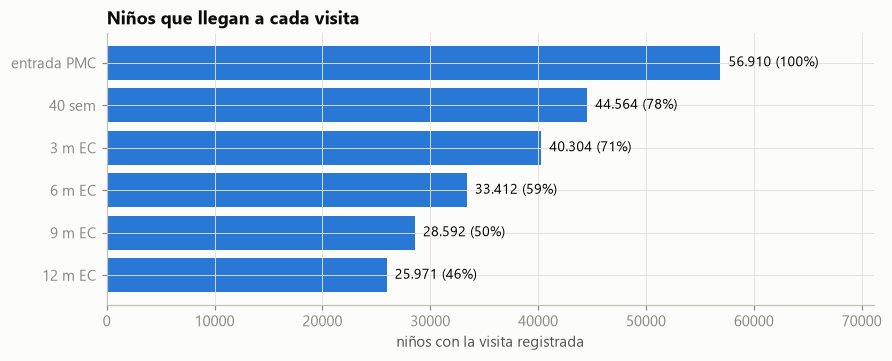

,no volvió,volvió a las 40 semanas
"edad gestacional (semanas, mediana)",34,34
días de hospitalización (mediana),8,8
"peso a la entrada (g, mediana)",2.200,2.125
ingreso del hogar (mediana),1.300.000,1.500.000
salió con oxígeno (%),"30,18","33,40"


**Qué vemos.** De 56.910 niños que entran al programa con fecha, llegan 78% a las 40 semanas y 46% a los 12 meses. Entre los que ya debían haber vuelto a las 40 semanas, 7,5% no volvió. La tabla compara a los que vuelven con los que no: si se parecen, la pérdida no sesga mucho los desenlaces; si no, hay que tenerlo en cuenta al leerlos. Por eso "no vuelve a la siguiente visita" es también un desenlace que el modelo predice. (75 s)

In [2]:
t0 = time.time()
diccionario = Carpetas(Path('..').resolve()).diccionario
sev = K.cargar_sevarti(diccionario)
CONFIG = CF.leer(D.leer(diccionario))   # the clinical configuration the experts keep in the dictionary
lector = AC.ModeloClinico(CONFIG)          # reads and cleans the data the way the models do
p_todo = lector.preparar(sev)
visitas = ['entrada PMC', '40 sem', '3 m EC', '6 m EC', '9 m EC', '12 m EC']
llegan = pd.Series({v: len(lector.asistieron(p_todo, v)) for v in visitas})
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(len(llegan)), llegan.values, color=G.SERIES[0])
ax.set_yticks(range(len(llegan)), llegan.index)
ax.invert_yaxis()
for i, v in enumerate(llegan.values):
    ax.text(v, i, f'  {fmt(v)} ({pct(100 * v / llegan.iloc[0])})', va='center', fontsize=9)
ax.set_title('Niños que llegan a cada visita')
ax.set_xlabel('niños con la visita registrada')
ax.margins(x=0.25)
plt.show()

des = next(d for d in CONFIG.desenlaces if d.clave == 'no_vuelve_40s')
y = lector.etiqueta(p_todo, des).dropna()
d = p_todo.datos


def primero(var):
    s = d[d.variable == var].drop_duplicates('sujeto').set_index('sujeto')
    return pd.to_numeric(s.valor, errors='coerce')


perfil = pd.DataFrame({
    'edad gestacional (semanas, mediana)': sev.sujetos.set_index('sujeto').eg_semanas,
    'días de hospitalización (mediana)': primero('hd_totaldiashospital'),
    'peso a la entrada (g, mediana)': primero('v196a'),
    'ingreso del hogar (mediana)': primero('csp_ingresomensual'),
    'salió con oxígeno (%)': 100 * (primero('hd_c_oxigenodependencia') == 1),
}).reindex(y.index)
comparacion = perfil.groupby(y.map({0.0: 'volvió a las 40 semanas', 1.0: 'no volvió'})).agg(
    {c: ('mean' if '%' in c else 'median') for c in perfil})
display(comparacion.T)
md(f'''**Qué vemos.** De {fmt(llegan.iloc[0])} niños que entran al programa con fecha, llegan {pct(100 * llegan['40 sem'] / llegan.iloc[0])} a las 40 semanas y {pct(100 * llegan['12 m EC'] / llegan.iloc[0])} a los 12 meses. Entre los que ya debían haber vuelto a las 40 semanas, {pct(100 * y.mean(), 1)} no volvió. La tabla compara a los que vuelven con los que no: si se parecen, la pérdida no sesga mucho los desenlaces; si no, hay que tenerlo en cuenta al leerlos. Por eso "no vuelve a la siguiente visita" es también un desenlace que el modelo predice. ({time.time() - t0:.0f} s)''')

## 2. Los desenlaces y cuándo se predicen

Los desenlaces, la visita en que se predice cada uno, cómo se lee de los datos y la regla simple con que se compara los configuran los expertos en la hoja "Desenlaces" del diccionario de variables; este informe usa los que están "En uso".

Cada desenlace se predice en una visita, solo con lo que se sabe hasta esa visita, y se lee de la visita siguiente. La división es la del modelo de anomalías: por año de nacimiento, sin niños repetidos, y los más recientes de cada régimen quedan para la prueba. Dentro de lo que se entrena, el nivel del riesgo de cada desenlace se fija con los niños más recientes cuyo desenlace ya se conoce, los más parecidos a los que se les va a calcular el riesgo. Para un desenlace temprano son los nacidos más recientes; para uno de los 12 meses, niños nacidos antes, que ya tuvieron tiempo de llegar a esa edad.

- **Readmisión:** el conteo de readmisiones que se anota en la visita siguiente es mayor que cero.
- **No vuelve:** el niño no tiene la visita siguiente, y la ventana de esa visita ya cerró. Solo cuenta si en la visita actual la siguiente todavía no había empezado: un niño que entra al programa ya en la ventana de las 40 semanas tiene en su entrada la visita de 40 semanas, y "no volver" a ella no es perderse.
- **Oxigenodependencia con diagnóstico:** displasia broncopulmonar o hipertensión pulmonar (códigos 1 y 2 de `consumo.categoria`; el 3 y el 9 son "sin diagnóstico"). Se predice temprano: la de los 3 meses al entrar al programa y la de los 12 meses a las 40 semanas. Con todos los años: el sistema anterior a 2022 anotaba "sin diagnóstico" casi siempre con el 3 y el actual con el 9, pero con los códigos 1 y 2 la tasa es la misma antes y después (1,7% a los 12 meses).
- **Desarrollo psicomotor bajo:** en el 10% inferior del puntaje de los niños de entrenamiento. Es una definición relativa, porque el diccionario no nombra el test: no depende de su escala ni de su punto de corte. Sigue abierta: si se sabe qué test es, se puede usar su corte oficial.

In [3]:
t0 = time.time()
tr, _, te, info = MA.dividir_por_tiempo(sev, (0.85, 0.0, 0.15))
tardias = lector.detectar_tardias(sev)
modelo = AC.ModeloClinico(CONFIG).ajustar(tr, tardias=tardias)
tabla = pd.DataFrame([{'desenlace': m.desenlace.nombre, 'visita': m.desenlace.momento,
                       'niños en entrenamiento': m.n_entrenamiento, 'casos': m.casos_entrenamiento,
                       '% casos': 100 * m.casos_entrenamiento / m.n_entrenamiento, 'nivel calibrado con': m.calibrado_con}
                      for m in modelo.modelos.values()]).set_index('desenlace')
display(info)
display(tabla)
md(f'''**Qué vemos.** Entrenar los {len(modelo.modelos)} modelos tomó {dec((time.time() - t0) / 60)} minutos.''' +
   (f''' No se usan {len(tardias)} variables que la base llena con retraso, meses después o solo cuando el niño vuelve a la siguiente visita (en las visitas de los últimos {CONFIG.dias_recientes} días y en los niños que todavía esperan su siguiente visita aparecen menos de la mitad de lo usual): {", ".join(tardias)}. En el momento de calcular el riesgo todavía faltarían y el modelo leería "falta" como riesgo; las que se llenan al volver, además, delatan el desenlace. La edad corregida de los 3 y 9 meses es de estas: antes de quitarla, el 62% de los niños pendientes de la visita de 6 meses quedaba entre el 10% de más riesgo de no volver.''' if tardias else '') +
   (f' Quedaron sin modelo: {"; ".join(f"{c} ({m})" for c, m in modelo.omitidos.items())}.' if modelo.omitidos else ''))

,sujetos,regimenes
entrenamiento,48041,2
calibración,0,2
prueba,8955,2


,visita,niños en entrenamiento,casos,% casos,nivel calibrado con
desenlace,,,,,
readmisión antes de las 40 semanas,entrada PMC,11376,1370,"12,04",nacidos de 2025 a 2025
readmisión entre las 40 semanas y los 3 meses,40 sem,8956,1070,"11,95",nacidos de 2025 a 2025
readmisión entre los 3 y los 6 meses,3 m EC,23188,1041,"4,49",nacidos de 2023 a 2025
readmisión entre los 6 y los 9 meses,6 m EC,19209,791,"4,12",nacidos de 2023 a 2025
readmisión entre los 9 y los 12 meses,9 m EC,16816,541,"3,22",nacidos de 2023 a 2025
no vuelve a la visita de 40 semanas,entrada PMC,14486,986,"6,81",nacidos de 2023 a 2025
no vuelve a la visita de 3 meses,40 sem,28954,3760,"12,99",nacidos de 2024 a 2025
no vuelve a la visita de 6 meses,3 m EC,29185,6010,"20,59",nacidos de 2024 a 2025
no vuelve a la visita de 9 meses,6 m EC,24383,5403,"22,16",nacidos de 2023 a 2025


**Qué vemos.** Entrenar los 14 modelos tomó 4,4 minutos. No se usan 3 variables que la base llena con retraso, meses después o solo cuando el niño vuelve a la siguiente visita (en las visitas de los últimos 90 días y en los niños que todavía esperan su siguiente visita aparecen menos de la mitad de lo usual): ec_3m, ec_9m, v301d. En el momento de calcular el riesgo todavía faltarían y el modelo leería "falta" como riesgo; las que se llenan al volver, además, delatan el desenlace. La edad corregida de los 3 y 9 meses es de estas: antes de quitarla, el 62% de los niños pendientes de la visita de 6 meses quedaba entre el 10% de más riesgo de no volver.

## 3. ¿Funciona? Validación con los niños más recientes

Aquí los desenlaces son la verdad, no hace falta meter errores. Para cada desenlace, en niños que el modelo nunca vio:

- **AUC:** qué tan bien ordena el riesgo (0,5 es azar, 1 es perfecto).
- **Casos en el riesgo más alto:** de los niños que tuvieron el evento, cuántos estaban entre el 10% con más riesgo. El modelo y la regla simple se comparan con el mismo número de niños. Es una vara de medida, no un umbral.
- **Regla simple:** el mismo modelo con solo las variables que cada desenlace nombra en "Comparar con" (hoy, edad gestacional, peso al nacer y peso a la entrada). Si el modelo no le gana, no vale la pena.

,visita,niños,% casos,AUC,AUC regla simple,casos en el riesgo más alto (%),"casos en el riesgo más alto, regla simple (%)","del riesgo más alto, con el evento (%)"
desenlace,,,,,,,,
readmisión antes de las 40 semanas,entrada PMC,1408,"10,30","0,74","0,63","26,21","17,24","26,95"
readmisión entre las 40 semanas y los 3 meses,40 sem,508,"11,02","0,61","0,53","16,07","12,50","17,65"
readmisión entre los 3 y los 6 meses,3 m EC,3385,"1,60","0,63","0,53","20,37","18,52","3,25"
readmisión entre los 6 y los 9 meses,6 m EC,2615,"1,99","0,59","0,47","17,31","9,62","3,44"
readmisión entre los 9 y los 12 meses,9 m EC,2295,"1,57","0,63","0,50","22,22","13,89","3,48"
no vuelve a la visita de 40 semanas,entrada PMC,2222,"10,80","0,67","0,57",25,"13,75","27,03"
no vuelve a la visita de 3 meses,40 sem,4338,"17,73","0,67","0,53","20,16","12,74","35,71"
no vuelve a la visita de 6 meses,3 m EC,4660,"29,55","0,57","0,49","13,07","9,59","38,63"
no vuelve a la visita de 9 meses,6 m EC,3855,"34,03","0,57","0,50","13,80","9,60","46,89"


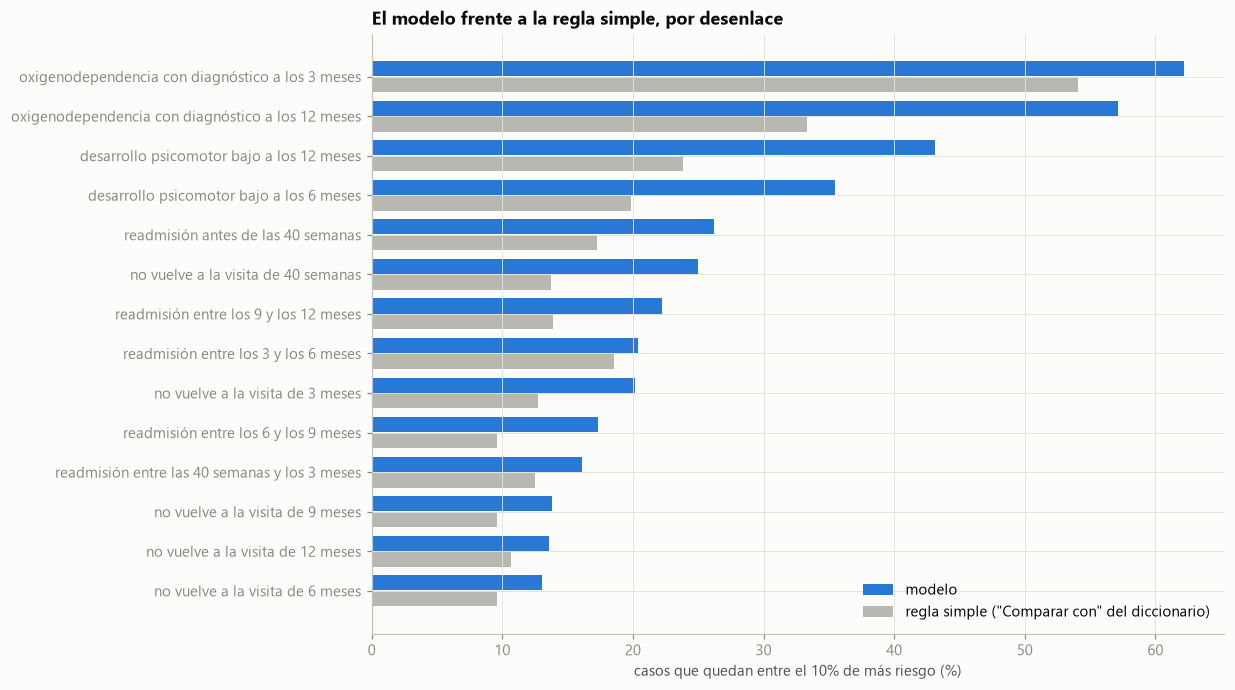

**Qué vemos.** El modelo le gana a la regla simple en **13 de 14** desenlaces. Donde mejor funciona es **oxigenodependencia con diagnóstico a los 3 meses** (AUC 0,93): el 62% de los casos queda entre el 10% de más riesgo. Donde peor, **no vuelve a la visita de 6 meses** (AUC 0,57). Un AUC cerca de 0,6 dice que con estos datos ese desenlace casi no se puede anticipar: el riesgo se calcula igual y su AUC queda en la ficha del modelo, para que quien lo presente sepa cuánto vale. (0,5 minutos.)

In [4]:
t0 = time.time()
ev, calibraciones, p_te = AC.evaluar(modelo, te)
columnas = ['visita', 'niños', '% casos', 'AUC', 'AUC regla simple', 'casos en el riesgo más alto (%)',
            'casos en el riesgo más alto, regla simple (%)', 'del riesgo más alto, con el evento (%)']
display(ev.rename(columns={'momento': 'visita'})[columnas])
orden = ev.sort_values('casos en el riesgo más alto (%)').index
fig, ax = plt.subplots(figsize=(10, 0.42 * len(orden) + 1.2))
yy = np.arange(len(orden))
ax.barh(yy + 0.2, ev.loc[orden, 'casos en el riesgo más alto (%)'], height=0.38, color=G.SERIES[0], label='modelo')
ax.barh(yy - 0.2, ev.loc[orden, 'casos en el riesgo más alto, regla simple (%)'], height=0.38, color='#b8b8b2',
        label='regla simple ("Comparar con" del diccionario)')
ax.set_yticks(yy, orden)
ax.set_xlabel('casos que quedan entre el 10% de más riesgo (%)')
ax.set_title('El modelo frente a la regla simple, por desenlace')
ax.legend(loc='lower right')
plt.show()
gana = (ev['AUC'] > ev['AUC regla simple'] + 0.02)
md(f'''**Qué vemos.** El modelo le gana a la regla simple en **{gana.sum()} de {len(ev)}** desenlaces. Donde mejor funciona es **{ev['AUC'].idxmax()}** (AUC {dec(ev['AUC'].max(), 2)}): el {pct(ev.loc[ev['AUC'].idxmax(), 'casos en el riesgo más alto (%)'])} de los casos queda entre el 10% de más riesgo. Donde peor, **{ev['AUC'].idxmin()}** (AUC {dec(ev['AUC'].min(), 2)}). Un AUC cerca de 0,6 dice que con estos datos ese desenlace casi no se puede anticipar: el riesgo se calcula igual y su AUC queda en la ficha del modelo, para que quien lo presente sepa cuánto vale. ({dec((time.time() - t0) / 60)} minutos.)''')

## 4. ¿El riesgo es creíble?

Si el modelo dice 20%, de cada 100 niños así unos 20 deberían tener el evento. Cada punto es una décima parte de los niños de prueba, ordenados por riesgo.

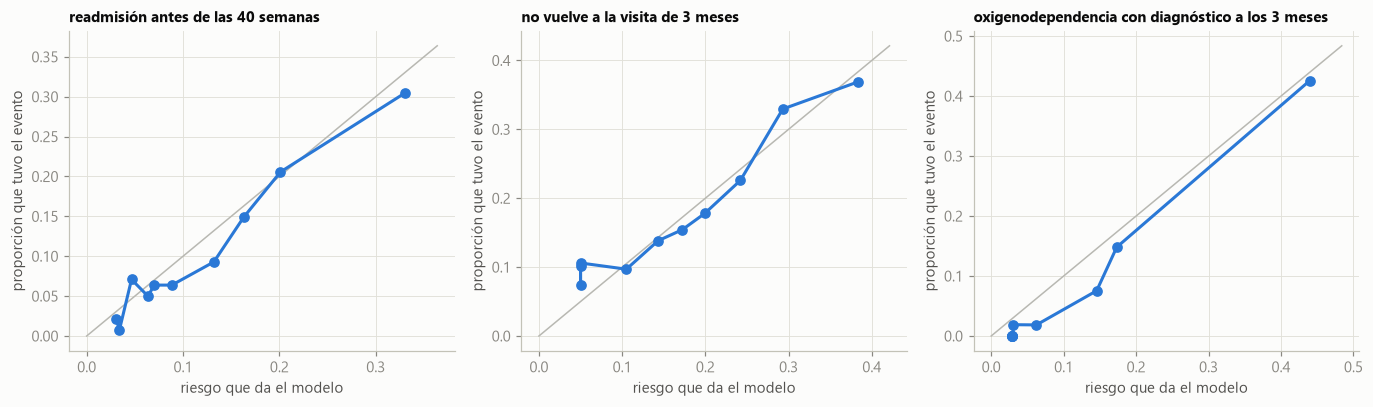

,riesgo medio (%),observado (%),riesgo / observado
readmisión antes de las 40 semanas,"11,60","10,29","1,13"
readmisión entre las 40 semanas y los 3 meses,"14,30","11,03","1,30"
readmisión entre los 3 y los 6 meses,"7,11","1,59","4,46"
readmisión entre los 6 y los 9 meses,"4,20","1,99","2,11"
readmisión entre los 9 y los 12 meses,"3,29","1,57","2,10"
no vuelve a la visita de 40 semanas,"11,05","10,80","1,02"
no vuelve a la visita de 3 meses,"16,88","17,73","0,95"
no vuelve a la visita de 6 meses,"27,29","29,55","0,92"
no vuelve a la visita de 9 meses,"28,95","34,03","0,85"
no vuelve a la visita de 12 meses,"31,96","29,71","1,08"


**Qué vemos.** Una cosa es cómo ordena a los niños (sección 3) y otra si el nivel cuadra: en 5 de 14 desenlaces el riesgo medio que da el modelo es más de 1,25 veces lo que de verdad pasó en los niños más recientes, sobre todo en **readmisión entre los 3 y los 6 meses** (4,5 veces). Es deriva en el tiempo: los nacidos más recientes tienen menos eventos que los del periodo con que se calibró. Por eso el modelo de uso diario se calibra con los niños más recientes cuyo desenlace ya se conoce y se recalibra en cada entrenamiento; antes de mostrar un porcentaje al médico, hay que confirmar en el periodo en silencio que el nivel cuadra.

In [5]:
claves = [c for c in ('readm_40s', 'no_vuelve_3m', 'oxigeno_3m') if c in calibraciones]
fig, axes = plt.subplots(1, len(claves), figsize=(4.2 * len(claves), 3.8), squeeze=False)
for ax, c in zip(axes[0], claves):
    t = calibraciones[c]
    tope = max(t.riesgo_medio.max(), t.observado.max()) * 1.1
    ax.plot([0, tope], [0, tope], color='#b8b8b2', linewidth=1)
    ax.plot(t.riesgo_medio, t.observado, 'o-', color=G.SERIES[0])
    ax.set_title(modelo.modelos[c].desenlace.nombre, fontsize=10)
    ax.set_xlabel('riesgo que da el modelo')
    ax.set_ylabel('proporción que tuvo el evento')
plt.tight_layout()
plt.show()
razon = pd.DataFrame({
    'riesgo medio (%)': {modelo.modelos[c].desenlace.nombre: 100 * t.riesgo_medio.mean() for c, t in calibraciones.items()},
    'observado (%)': {modelo.modelos[c].desenlace.nombre: 100 * t.observado.mean() for c, t in calibraciones.items()},
})
razon['riesgo / observado'] = razon['riesgo medio (%)'] / razon['observado (%)']
display(razon)
sobre = razon[razon['riesgo / observado'] > 1.25]
md(f'''**Qué vemos.** Una cosa es cómo ordena a los niños (sección 3) y otra si el nivel cuadra: en {len(sobre)} de {len(razon)} desenlaces el riesgo medio que da el modelo es más de 1,25 veces lo que de verdad pasó en los niños más recientes''' +
   (f''', sobre todo en **{razon['riesgo / observado'].idxmax()}** ({dec(razon['riesgo / observado'].max(), 1)} veces). Es deriva en el tiempo: los nacidos más recientes tienen menos eventos que los del periodo con que se calibró. Por eso el modelo de uso diario se calibra con los niños más recientes cuyo desenlace ya se conoce y se recalibra en cada entrenamiento; antes de mostrar un porcentaje al médico, hay que confirmar en el periodo en silencio que el nivel cuadra.''' if len(sobre) else '. Un 20% es de verdad un 20%, y eso es lo que permite mostrarle el número al médico.'))

## 5. Qué mira el modelo

Lo que más usa cada modelo para ordenar el riesgo. Para cada niño, además, sale su porqué: las tres variables que más le suben el riesgo (`python -m clinico riesgos`).

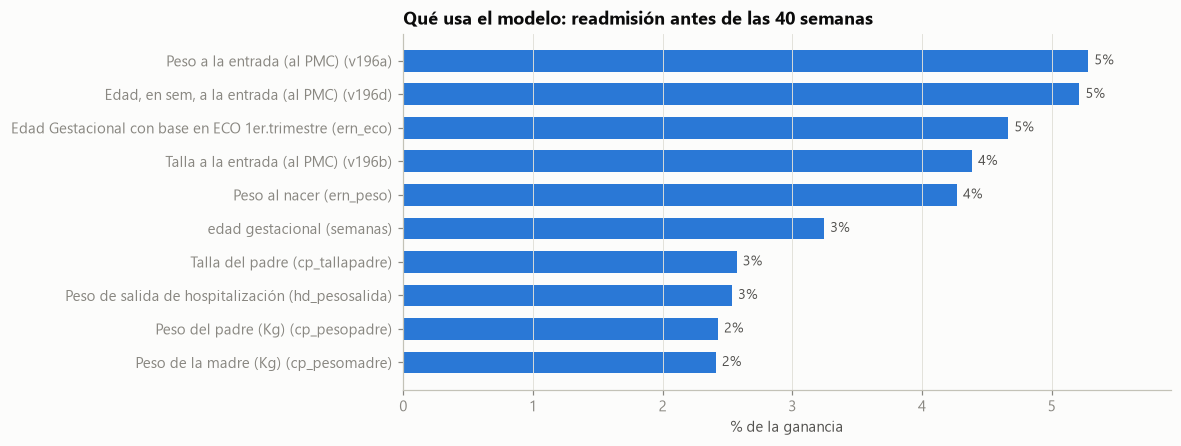

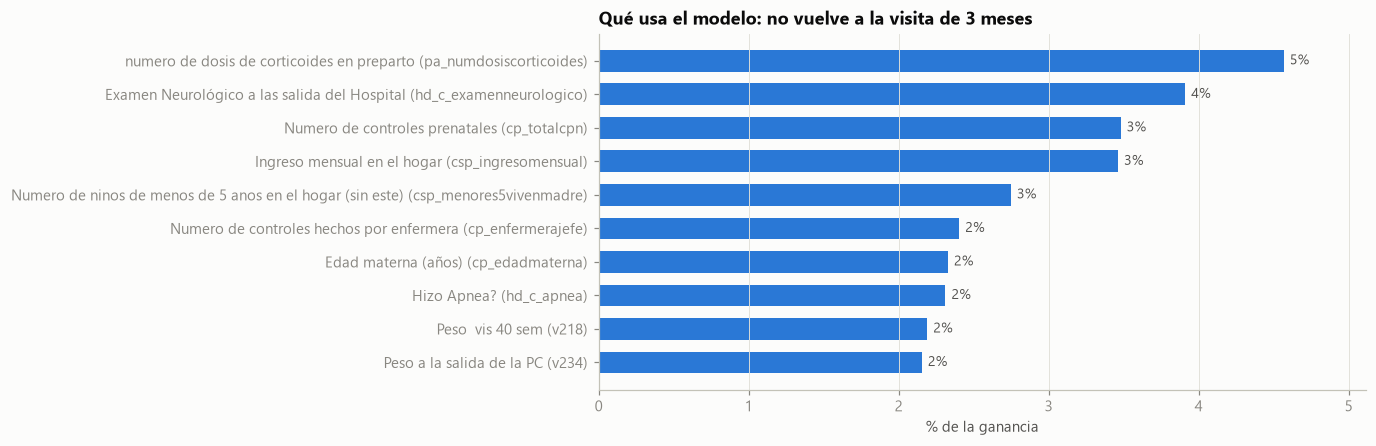

In [6]:
for c in [c for c in ('readm_40s', 'no_vuelve_3m') if c in modelo.modelos]:
    G.barh(100 * AC.importancia(modelo.modelos[c], modelo.etiquetas), f'Qué usa el modelo: {modelo.modelos[c].desenlace.nombre}',
           '% de la ganancia', fmt='{:.0f}%')
    plt.show()

## 6. ¿Funciona igual para todos?

Un modelo puede acertar en promedio y fallar en un grupo. Revisamos la readmisión antes de las 40 semanas por edad gestacional y por ingreso del hogar: el riesgo medio que da el modelo debería parecerse a lo observado en cada grupo. (Por sede ya no se puede: la base no la trae.)

In [7]:
clave = 'readm_40s'
X_te = modelo.matriz(p_te, modelo.modelos[clave].desenlace.momento)
bandas_eg = pd.cut(X_te.eg_semanas, [0, 31.99, 36.99, 50], labels=['menos de 32 semanas', '32 a 36', '37 o más'])
ingreso = X_te.get('csp_ingresomensual')
terciles = pd.qcut(ingreso, 3, labels=['ingreso bajo', 'ingreso medio', 'ingreso alto']) if ingreso is not None else None
for nombre, grupos in (('edad gestacional', bandas_eg), ('ingreso del hogar', terciles)):
    if grupos is None:
        continue
    t = AC.por_grupo(modelo, p_te, clave, grupos)
    t['% observado'], t['% riesgo medio'] = 100 * t.observado, 100 * t.riesgo_medio
    display(t[['niños', 'casos', '% observado', '% riesgo medio']].rename_axis(nombre))
md('''**Qué vemos.** Hay que leer dos cosas por grupo. Si el riesgo medio queda por debajo de lo observado, el modelo subestima a esos niños; si queda muy por encima (la deriva de la sección 4), los sobreestima. Esto se repite cuando los médicos revisen su hoja y al final del periodo en silencio.''')

,niños,casos,% observado,% riesgo medio
edad gestacional,,,,
menos de 32 semanas,68,13,"19,12","19,04"
32 a 36,795,88,"11,07","12,84"
37 o más,545,44,"8,07","8,88"


,niños,casos,% observado,% riesgo medio
ingreso del hogar,,,,
ingreso bajo,93,7,"7,53","11,92"
ingreso medio,406,53,"13,05","11,50"
ingreso alto,907,85,"9,37","11,63"


**Qué vemos.** Hay que leer dos cosas por grupo. Si el riesgo medio queda por debajo de lo observado, el modelo subestima a esos niños; si queda muy por encima (la deriva de la sección 4), los sobreestima. Esto se repite cuando los médicos revisen su hoja y al final del periodo en silencio.

## 7. Crecimiento contra la curva de la OMS

Desde las 40 semanas, cada peso, talla y perímetro cefálico se pasa a puntaje z por edad corregida con los estándares de la OMS. Antes de las 40 semanas la OMS no aplica y ese tramo no se evalúa; desde las 40 semanas cubre todas las visitas del seguimiento. Los datos que el modelo de anomalías reconoce como errores no entran, y un valor a más de 6 DE (la regla de la OMS para valores biológicamente improbables), o una medida con una edad que no es la de su visita, se manda a revisar como dato, no como hallazgo clínico. Si el diccionario le da a una visita dos variables de la misma medida, cuenta una: la de la ventana de la visita y, entre esas, la más tardía.

datos  z_mediano  % por debajo de -2 DE  % cae más de 1 DE  % revisar el dato
etapa   concepto                                                                                         
40 sem  perimetro_cefalico   6323       0,53                   1,06                  0               0,06
        peso                20895      -0,77                  10,25                  0               1,23
        talla               20243      -1,11                  19,93                  0               1,37
3 m EC  perimetro_cefalico  39712       0,05                   3,84               2,09               1,33
        peso                39881      -0,66                  10,13               5,57               1,30
        talla               39808      -1,20                  21,91               5,26               1,49
6 m EC  perimetro_cefalico  33011       0,08                   3,06               3,04               1,58
        peso                33067      -0,73                  11,55               3,08               1,61
        talla               33065      -1,14                  19,80               4,54               1,70
9 m EC  perimetro_cefalico  28176       0,14                   3,18               2,54               1,60
        peso                28231      -0,67                  11,11               1,43               1,63
        talla               28153      -1,05                  18,29               3,19               1,66
12 m EC perimetro_cefalico  25625       0,20                   3,49               2,35               1,89
        peso                25660      -0,65                  10,44               1,11               1,91
        talla               25633      -1,06                  18,04               2,83               2,02

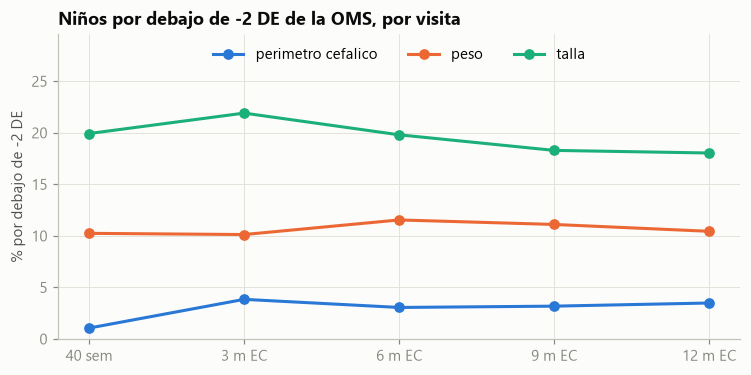

**Qué vemos.** 57.198 datos de crecimiento quedan por debajo de -2 DE o caen más de 1 DE, y 753 quedan a más de 6 DE y 5.905 tienen una edad que no es la de su visita: esos no son un hallazgo clínico sino un dato para revisar. A los 12 meses el 10,4% de los pesos queda por debajo de -2 DE de la OMS: eso es lo que el modelo de anomalías nunca habría marcado, porque en esta base es común. La caída de más de 1 DE entre visitas es la señal más temprana: aparece antes de que el niño cruce el -2.

In [8]:
c = lector.crecimiento(p_todo)
resumen = c.groupby(['etapa', 'concepto']).agg(datos=('z', 'size'), z_mediano=('z', 'median'),
                                               bajo=('bajo', 'mean'), cae=('cae', 'mean'), revisar=('revisar', 'mean'))
resumen[['% por debajo de -2 DE', '% cae más de 1 DE', '% revisar el dato']] = 100 * resumen[['bajo', 'cae', 'revisar']]
orden_etapas = [e for e in CONFIG.etapas_crecimiento if e in resumen.index.get_level_values(0)]
resumen = resumen.reindex(orden_etapas, level=0)
display(resumen[['datos', 'z_mediano', '% por debajo de -2 DE', '% cae más de 1 DE', '% revisar el dato']])
ancho = resumen['% por debajo de -2 DE'].unstack()
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, concepto in enumerate(ancho.columns):
    ax.plot(range(len(ancho)), ancho[concepto], 'o-', color=G.SERIES[i], label=concepto.replace('_', ' '))
ax.set_xticks(range(len(ancho)), ancho.index)
ax.set_ylabel('% por debajo de -2 DE')
ax.set_title('Niños por debajo de -2 DE de la OMS, por visita')
ax.set_ylim(0, ancho.max().max() * 1.35)
ax.legend(loc='upper center', ncols=len(ancho.columns), frameon=False)
plt.show()
peso_12 = resumen.loc[('12 m EC', 'peso'), '% por debajo de -2 DE'] if ('12 m EC', 'peso') in resumen.index else np.nan
md(f'''**Qué vemos.** {fmt(int((c.bajo | c.cae).sum()))} datos de crecimiento quedan por debajo de -2 DE o caen más de 1 DE, y {fmt(int(c.improbable.sum()))} quedan a más de 6 DE y {fmt(int((c.revisar & ~c.improbable).sum()))} tienen una edad que no es la de su visita: esos no son un hallazgo clínico sino un dato para revisar. A los 12 meses el {pct(peso_12, 1)} de los pesos queda por debajo de -2 DE de la OMS: eso es lo que el modelo de anomalías nunca habría marcado, porque en esta base es común. La caída de más de 1 DE entre visitas es la señal más temprana: aparece antes de que el niño cruce el -2.''')

## 8. Uso

| Orden | Qué hace |
|---|---|
| `python -m clinico entrenar` | Repite esta validación, entrena con todos los datos y guarda el modelo con su ficha en `interno/clinico/modelos/` |
| `python -m clinico riesgos --silencio` | Calcula y guarda los riesgos **sin entregarlos**: es el periodo en silencio |
| `python -m clinico silencio` | Compara lo guardado en silencio con lo que pasó después |
| `python -m retroalimentacion medicos` | Archivo ciego para los médicos: niños de riesgo alto y del resto mezclados; responden "¿Le preocupa?" con Sí, No o No sé |
| `python -m retroalimentacion revision` | Con el archivo ya respondido en `entradas/retroalimentacion/`, si los niños de riesgo alto les preocuparon más que el resto |
| `python -m clinico riesgos` | Riesgo de cada desenlace de los niños con visita desde la entrega anterior cuya siguiente visita todavía no pasa (a los demás ya es tarde), con su posición y su porqué, y el crecimiento fuera de la curva de lo medido en ese periodo. El mismo corte repite su periodo |

`python pipeline.py` corre todo en orden, con el modelo de anomalías primero.

Los riesgos quedan en `salidas/riesgos/`; la hoja de los médicos (`python -m retroalimentacion medicos`) en `entradas/retroalimentacion/`; tienen datos por niño: no se comparten fuera del equipo clínico.

## 9. Qué sigue

- **Validación clínica:** el archivo de `python -m retroalimentacion medicos` respondido por médicos, y un periodo en silencio antes de entregar los riesgos.
- **Decisiones abiertas.** Por ahora el modelo queda como está. Las que lo tocan: el desarrollo "bajo" como el 10% inferior (sección 2), el crecimiento solo desde las 40 semanas, sin curva de prematuros, y los criterios de crecimiento (-2 DE, caída de 1 DE, ±6 DE para revisar el dato).
- **Pérdida de seguimiento:** los desenlaces de visitas tardías solo se conocen en los que vuelven (sección 1). Es la principal limitación de los desenlaces tardíos, y por eso el riesgo de no volver se calcula aparte.